# Telco Customer Churn Prediction: ML Lifecycle

### **Setup:** Import libraries and settings

In [ ]:
import sys, subprocess, warnings, json, hashlib
from pathlib import Path
warnings.filterwarnings("ignore")

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
_ensure("xgboost"); _ensure("shap"); _ensure("joblib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score, brier_score_loss,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup complete")

Setup complete


### **Stage 1:** Problem Definition

In [ ]:
SUCCESS_CRITERIA = {"roc_auc": 0.80, "recall": 0.75, "top_decile_lift": 2.0}
THRESHOLD_BETA = 2.0     # F-beta used to pick the decision threshold (2 = recall counts double; 1.0 = plain F1)
TEST_SIZE = 0.20
CV_FOLDS = 5
TARGET, ID_COL = "Churn", "customerID"
print("Success criteria:", SUCCESS_CRITERIA)

Success criteria: {'roc_auc': 0.8, 'recall': 0.75, 'top_decile_lift': 2.0}


### **Stage 2:** Data Collection
This loads CSV file and validates the schema

In [ ]:
DATA_PATH = Path("Telco-Customer-Churn.csv")      # <- your renamed file in the Colab Files panel

if not DATA_PATH.exists():
    # fall back to any CSV with "churn" in its name (e.g. if the name differs slightly)
    matches = sorted(Path(".").glob("*[Cc]hurn*.csv"))
    if matches:
        DATA_PATH = matches[0]
        print("Using:", DATA_PATH)
    else:
        try:
            from google.colab import files           # only exists on Colab
            print("Upload the Telco churn CSV ...")
            DATA_PATH = Path(next(iter(files.upload())))
        except ImportError:
            raise FileNotFoundError(f"Put {DATA_PATH} in the same folder as this notebook (or edit DATA_PATH).")

raw = pd.read_csv(DATA_PATH)

EXPECTED = {"customerID","gender","SeniorCitizen","Partner","Dependents","tenure","PhoneService","MultipleLines",
            "InternetService","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
            "StreamingMovies","Contract","PaperlessBilling","PaymentMethod","MonthlyCharges","TotalCharges","Churn"}
missing = EXPECTED - set(raw.columns)
assert not missing, f"Missing columns: {sorted(missing)}"

provenance = {
    "source": "https://www.kaggle.com/datasets/blastchar/telco-customer-churn",
    "file": DATA_PATH.name,
    "sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16] + "...",
    "rows": len(raw), "columns": raw.shape[1],
    "duplicate_customer_ids": int(raw[ID_COL].duplicated().sum()),
}
print(json.dumps(provenance, indent=2))
raw.head()

{
  "source": "https://www.kaggle.com/datasets/blastchar/telco-customer-churn",
  "file": "Telco-Customer-Churn.csv",
  "sha256": "88be4b93fbe0cc83...",
  "rows": 7043,
  "columns": 21,
  "duplicate_customer_ids": 0
}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Stage 03:** Data Cleaning & Preprocessing

1. TotalCharges: Converted text to numeric. Missing 11 values replaced with zero due to tenure being zero.

2. SeniorCitizen: Converted binary 0/1 values into consistent Yes/No categorical format.

3. Churn: Transformed categorical values into binary 1/0 format for modeling.

In [ ]:
blank = raw["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges:", blank.sum(), "| all have tenure 0:", bool((raw.loc[blank, "tenure"] == 0).all()))

def clean(df):
    df = df.copy().drop_duplicates(subset=ID_COL)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
    df.loc[(df["tenure"] == 0) & df["TotalCharges"].isna(), "TotalCharges"] = 0.0
    assert df["TotalCharges"].notna().all(), "unexpected missing TotalCharges"
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    df[TARGET] = (df[TARGET] == "Yes").astype(int)
    return df.reset_index(drop=True)

df = clean(raw)
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=RANDOM_STATE)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(f"train={len(train_df)}  test={len(test_df)}  churn rate: train {train_df[TARGET].mean():.1%} | test {test_df[TARGET].mean():.1%}")

Blank TotalCharges: 11 | all have tenure 0: True
train=5634  test=1409  churn rate: train 26.5% | test 26.5%


### **Stage 04:** Exploratory Data Analysis (EDA)

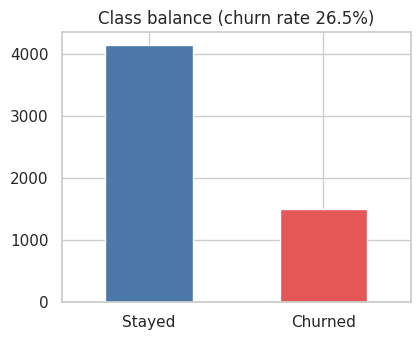

In [ ]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
train_df[TARGET].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(ax=ax, color=["#4C78A8", "#E45756"])
ax.set_title(f"Class balance (churn rate {train_df[TARGET].mean():.1%})"); ax.set_xlabel(""); plt.xticks(rotation=0); plt.show()

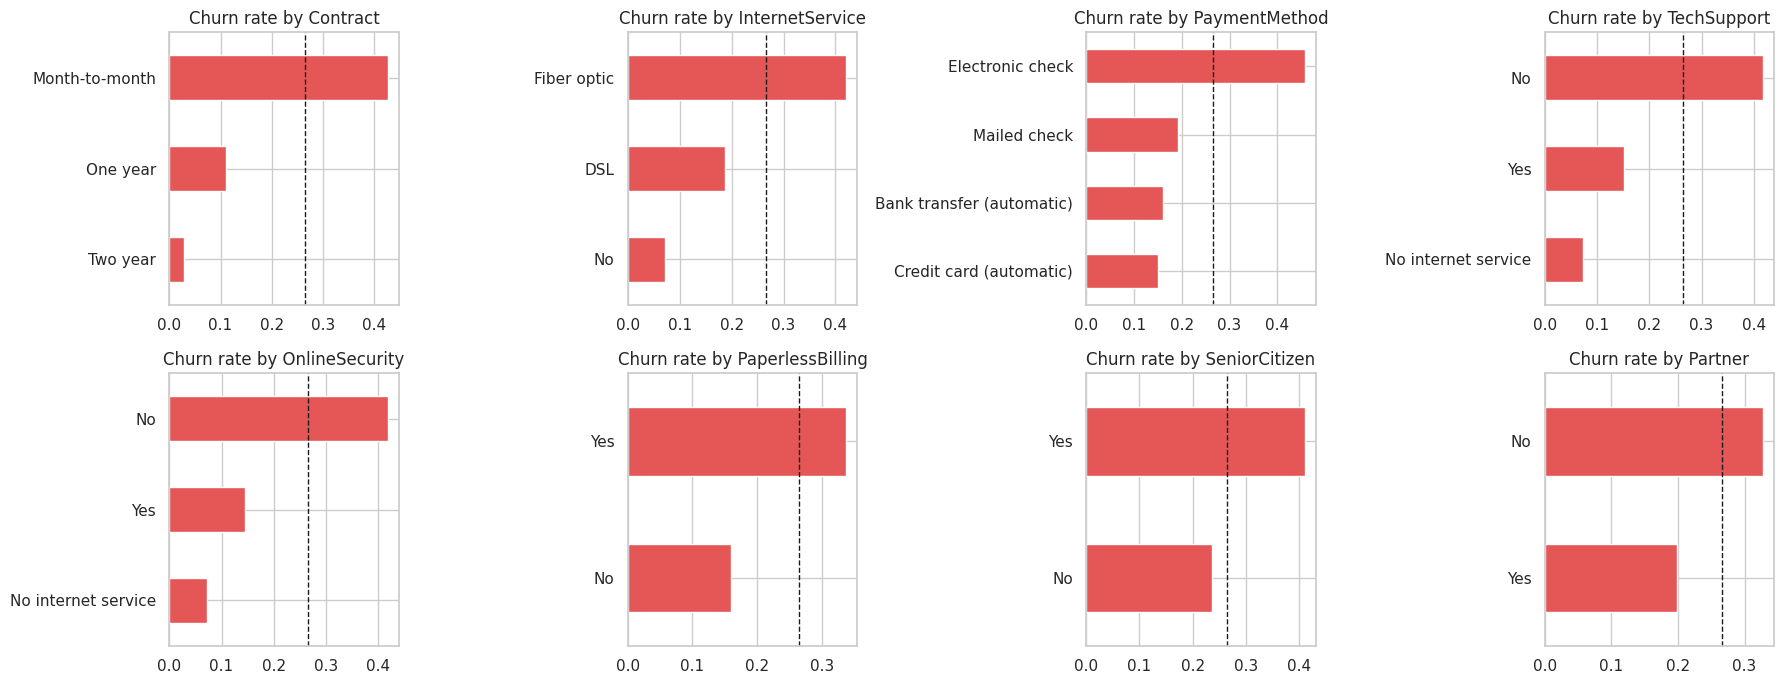

In [ ]:
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), cols):
    train_df.groupby(c)[TARGET].mean().sort_values().plot.barh(ax=ax, color="#E45756")
    ax.axvline(train_df[TARGET].mean(), color="k", ls="--", lw=1); ax.set_title(f"Churn rate by {c}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

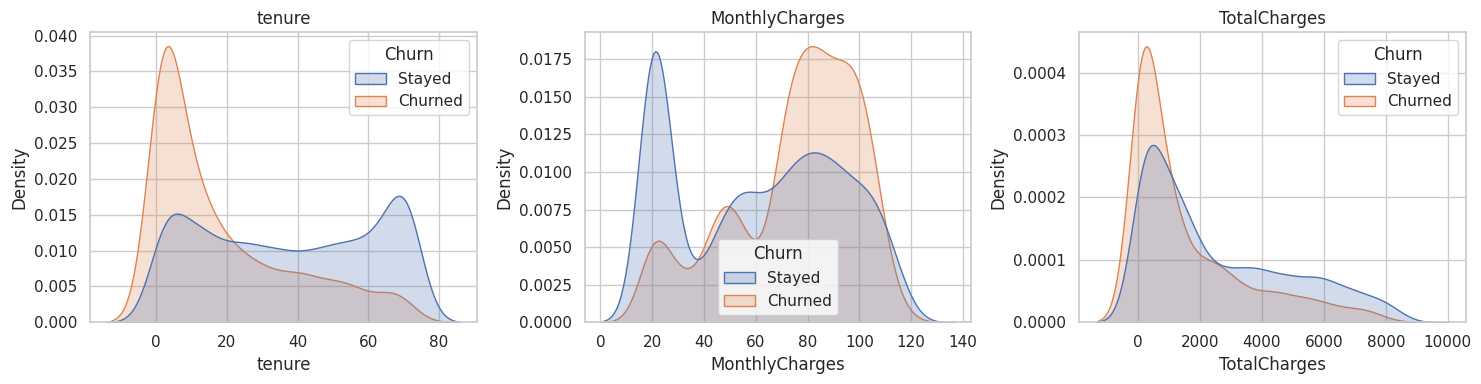

Churn rate by tenure bucket:
tenure
(-1, 12]    0.473
(12, 24]    0.286
(24, 48]    0.202
(48, 72]    0.099
Name: Churn, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=train_df, x=c, hue=train_df[TARGET].map({0: "Stayed", 1: "Churned"}), common_norm=False, fill=True, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

print("Churn rate by tenure bucket:")
print(train_df.groupby(pd.cut(train_df["tenure"], [-1, 12, 24, 48, 72]))[TARGET].mean().round(3))

### **Stage 05:** Feature Engineering & Selection

Preprocessing

In [ ]:
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
ALL_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "n_addon_services", "avg_monthly_spend", "charge_delta"]
ALL_CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
                   "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                   "Contract", "PaperlessBilling", "PaymentMethod", "tenure_group", "has_family", "autopay"]

def add_features(d):
    d = d.copy()
    d["n_addon_services"] = (d[ADDONS] == "Yes").sum(axis=1)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"].clip(lower=1), d["MonthlyCharges"])
    d["charge_delta"] = d["MonthlyCharges"] - d["avg_monthly_spend"]
    d["tenure_group"] = pd.cut(d["tenure"], [-1, 12, 24, 48, 60, 100],
                               labels=["0-12m", "13-24m", "25-48m", "49-60m", "60m+"]).astype(str)
    d["has_family"] = np.where((d["Partner"] == "Yes") | (d["Dependents"] == "Yes"), "Yes", "No")
    d["autopay"] = np.where(d["PaymentMethod"].str.contains("automatic"), "Yes", "No")
    return d

def make_xy(d):
    return add_features(d)[ALL_NUMERIC + ALL_CATEGORICAL], d[TARGET]

def build_preprocessor(numeric, categorical, scale=True):
    parts = []
    if numeric:
        parts.append(("num", StandardScaler() if scale else "passthrough", numeric))
    if categorical:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), categorical))
    return ColumnTransformer(parts, verbose_feature_names_out=False)

X_train, y_train = make_xy(train_df)
X_test,  y_test  = make_xy(test_df)
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print("Candidate features:", X_train.shape[1])

Candidate features: 25


Selection

In [ ]:
def cv_auc(numeric, categorical):
    pipe = Pipeline([("prep", build_preprocessor(numeric, categorical, True)),
                     ("clf", LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])
    return cross_val_score(pipe, X_train[numeric + categorical], y_train, cv=cv, scoring="roc_auc").mean()

def backward_selection(tolerance=0.0005, min_features=5):
    num, cat = list(ALL_NUMERIC), list(ALL_CATEGORICAL)
    full = cv_auc(num, cat)
    history = [{"step": 0, "removed": "(none)", "n_features": len(num) + len(cat), "cv_auc": full}]
    while len(num) + len(cat) > min_features:
        options = [("num", c) for c in num] + [("cat", c) for c in cat]
        def trial(kind, col):
            n = [c for c in num if not (kind == "num" and c == col)]
            k = [c for c in cat if not (kind == "cat" and c == col)]
            return kind, col, cv_auc(n, k)
        kind, col, auc = max(Parallel(n_jobs=-1)(delayed(trial)(k, c) for k, c in options), key=lambda r: r[2])
        if auc < full - tolerance:
            break
        (num if kind == "num" else cat).remove(col)
        history.append({"step": len(history), "removed": col, "n_features": len(num) + len(cat), "cv_auc": auc})
    return num, cat, pd.DataFrame(history)

numeric, categorical, sel_history = backward_selection()
FEATURES = numeric + categorical
display(sel_history.round(4))
print(f"\n{sel_history.iloc[0].n_features} candidates -> {len(FEATURES)} selected:", FEATURES)

,step,removed,n_features,cv_auc
0,0,(none),25,0.8452
1,1,charge_delta,24,0.8457
2,2,gender,23,0.8460
3,3,has_family,22,0.8463
4,4,avg_monthly_spend,21,0.8465
5,5,Partner,20,0.8467
6,6,StreamingTV,19,0.8468
7,7,StreamingMovies,18,0.8472
8,8,MonthlyCharges,17,0.8473
9,9,autopay,16,0.8473



25 candidates -> 9 selected: ['tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'TechSupport', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


### **Stage 06:** Model Selection

Compares four model families using 5-fold stratified cross-validation on the training set:

*   Logistic Regression
*   Random Forest
*   Histogram Gradient Boosting
*   XGBoost




In [ ]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scaled = lambda: build_preprocessor(numeric, categorical, True)    # linear model needs scaling
plain  = lambda: build_preprocessor(numeric, categorical, False)   # trees don't

models = {
    "logreg": (Pipeline([("prep", scaled()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
               {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "random_forest": (Pipeline([("prep", plain()), ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))]),
               {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [3, 5, 10, 20], "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "hist_gb": (Pipeline([("prep", plain()), ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
               {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_depth": [2, 3, 4, 6], "clf__max_iter": [100, 200, 400], "clf__l2_regularization": [0.0, 1.0, 5.0]}),
    "xgboost": (Pipeline([("prep", plain()), ("clf", XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist"))]),
               {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [2, 3, 4, 5], "clf__learning_rate": [0.02, 0.05, 0.1],
                "clf__subsample": [0.7, 0.9, 1.0], "clf__colsample_bytree": [0.6, 0.8, 1.0], "clf__min_child_weight": [1, 3, 5]}),
}

rows = []
for name, (pipe, _) in models.items():
    r = cross_validate(clone(pipe), X_train[FEATURES], y_train, cv=cv,
                       scoring={"roc_auc": "roc_auc", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
                                "pr_auc": "average_precision", "recall": "recall", "precision": "precision", "f1": "f1"})
    rows.append({"model": name, **{k[5:]: v.mean() for k, v in r.items() if k.startswith("test_")}, "roc_auc_std": r["test_roc_auc"].std()})
comparison = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
best_name = comparison.loc[0, "model"]
display(comparison.round(4)); print("Selected model family:", best_name)

,model,roc_auc,accuracy,balanced_accuracy,pr_auc,recall,precision,f1,roc_auc_std
0,logreg,0.8447,0.7441,0.7602,0.6582,0.7946,0.5118,0.6224,0.0113
1,hist_gb,0.8356,0.7519,0.7557,0.6440,0.7639,0.5224,0.6204,0.0095
2,xgboost,0.8177,0.7554,0.7419,0.6044,0.7130,0.5293,0.6075,0.0128
3,random_forest,0.8065,0.7652,0.7141,0.5887,0.6054,0.5529,0.5778,0.0147


Selected model family: logreg


### **Stage 07:** Model Training

In [ ]:
pipe, grid = models[best_name]
n_combos = int(np.prod([len(v) for v in grid.values()]))
search = RandomizedSearchCV(pipe, grid, n_iter=min(25, n_combos), cv=cv, scoring="roc_auc",
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(X_train[FEATURES], y_train)
model = search.best_estimator_
print("Best params :", search.best_params_)
print(f"Best CV AUC : {search.best_score_:.4f}")

Best params : {'clf__C': 0.03}
Best CV AUC : 0.8448


### **Stage 08:** Model Evaluation & Tuning

Chosen threshold (F2-optimal on out-of-fold training predictions): 0.31


,test
roc_auc,0.8392
pr_auc,0.6280
accuracy,0.6487
precision,0.4252
recall,0.9198
f1,0.5816
brier,0.1682


Reference: always predicting 'stay' gives accuracy 0.735


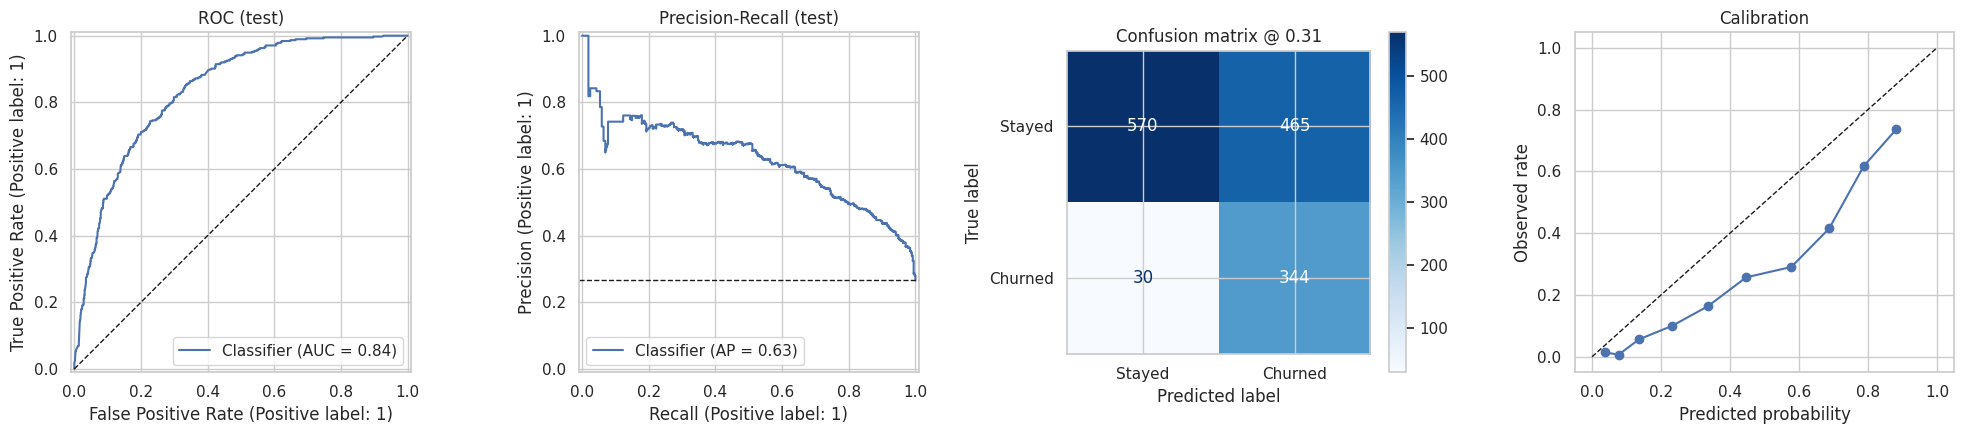

In [ ]:
oof = cross_val_predict(clone(model), X_train[FEATURES], y_train, cv=cv, method="predict_proba")[:, 1]
grid_t = np.linspace(0.05, 0.95, 91)
threshold = float(grid_t[np.argmax([fbeta_score(y_train, oof >= t, beta=THRESHOLD_BETA) for t in grid_t])])
print(f"Chosen threshold (F{THRESHOLD_BETA:g}-optimal on out-of-fold training predictions): {threshold:.2f}")

proba = model.predict_proba(X_test[FEATURES])[:, 1]
pred = proba >= threshold
metrics = {"roc_auc": roc_auc_score(y_test, proba), "pr_auc": average_precision_score(y_test, proba),
           "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
           "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "brier": brier_score_loss(y_test, proba)}
display(pd.Series(metrics, name="test").round(4).to_frame())
print(f"Reference: always predicting 'stay' gives accuracy {1 - y_test.mean():.3f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0]); axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC (test)")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1]); axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set_title("Precision-Recall (test)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[2], cmap="Blues", display_labels=["Stayed", "Churned"]); axes[2].set_title(f"Confusion matrix @ {threshold:.2f}")
frac, mean = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
axes[3].plot(mean, frac, "o-"); axes[3].plot([0, 1], [0, 1], "k--", lw=1); axes[3].set(title="Calibration", xlabel="Predicted probability", ylabel="Observed rate")
plt.tight_layout(); plt.show()

Accuracy at different decision thresholds

In [ ]:
from sklearn.metrics import balanced_accuracy_score, classification_report
best_t = lambda f: float(grid_t[np.argmax([f(y_train, oof >= t) for t in grid_t])])
strategies = {"Default 0.5": 0.5,
              "F1-optimal": best_t(lambda y, p: f1_score(y, p)),
              "Accuracy-optimal": best_t(accuracy_score),
              "Recall-first (F2) - used": threshold}
rows = []
for name, t in strategies.items():
    pr = proba >= t
    rows.append({"strategy": name, "threshold": round(t, 2), "accuracy": accuracy_score(y_test, pr),
                 "balanced_accuracy": balanced_accuracy_score(y_test, pr), "precision": precision_score(y_test, pr),
                 "recall": recall_score(y_test, pr), "f1": f1_score(y_test, pr)})
acc_table = pd.DataFrame(rows)
display(acc_table.round(3))
print(f"Baseline accuracy (always predict 'stay'): {1 - y_test.mean():.3f}")

acc_t = strategies["Accuracy-optimal"]
print(f"\nClassification report at the accuracy-optimal threshold ({acc_t:.2f}):")
print(classification_report(y_test, proba >= acc_t, target_names=["Stayed", "Churned"], digits=3))

,strategy,threshold,accuracy,balanced_accuracy,precision,recall,f1
0,Default 0.5,0.50,0.740,0.754,0.507,0.783,0.616
1,F1-optimal,0.59,0.771,0.753,0.554,0.714,0.624
2,Accuracy-optimal,0.71,0.796,0.714,0.638,0.537,0.583
3,Recall-first (F2) - used,0.31,0.649,0.735,0.425,0.920,0.582


Baseline accuracy (always predict 'stay'): 0.735

Classification report at the accuracy-optimal threshold (0.71):
              precision    recall  f1-score   support

      Stayed      0.842     0.890     0.865      1035
     Churned      0.638     0.537     0.583       374

    accuracy                          0.796      1409
   macro avg      0.740     0.714     0.724      1409
weighted avg      0.788     0.796     0.790      1409



Lift by risk decile

,customers,churners,churn_rate,lift,cum_capture
decile,,,,,
1,141,103,0.730,2.752,0.275
2,141,88,0.624,2.351,0.511
3,141,58,0.411,1.550,0.666
4,141,41,0.291,1.095,0.775
5,141,36,0.255,0.962,0.872
6,140,23,0.164,0.619,0.933
7,141,14,0.099,0.374,0.971
8,141,8,0.057,0.214,0.992
9,141,1,0.007,0.027,0.995


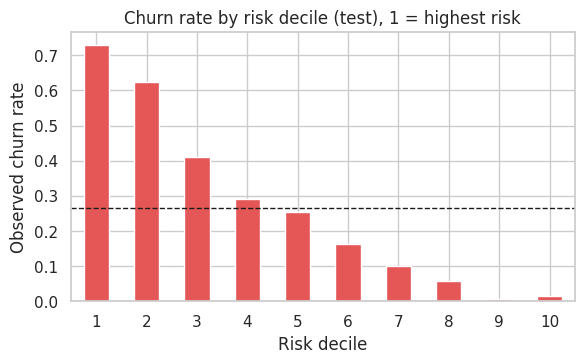

In [ ]:
d = pd.DataFrame({"y": y_test.to_numpy(), "p": proba})
d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = d.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"))
lift["churn_rate"] = lift["churners"] / lift["customers"]
lift["lift"] = lift["churn_rate"] / d["y"].mean()
lift["cum_capture"] = lift["churners"].cumsum() / d["y"].sum()
display(lift.round(3))

ax = lift["churn_rate"].plot.bar(figsize=(6.5, 3.5), color="#E45756"); ax.axhline(d["y"].mean(), color="k", ls="--", lw=1)
ax.set(title="Churn rate by risk decile (test), 1 = highest risk", xlabel="Risk decile", ylabel="Observed churn rate")
plt.xticks(rotation=0); plt.show()

Interpretation: why does the model flag a customer?

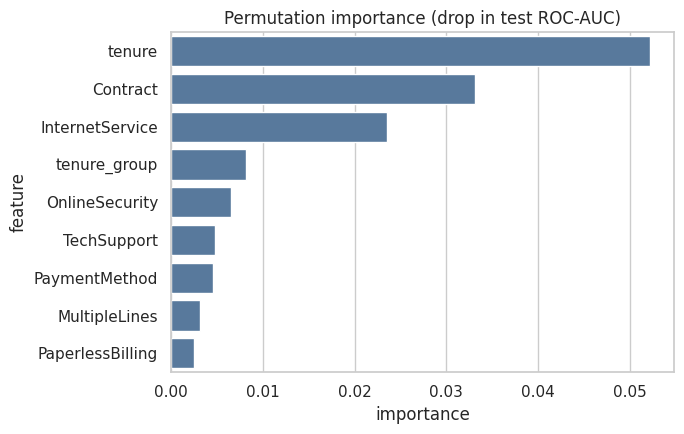

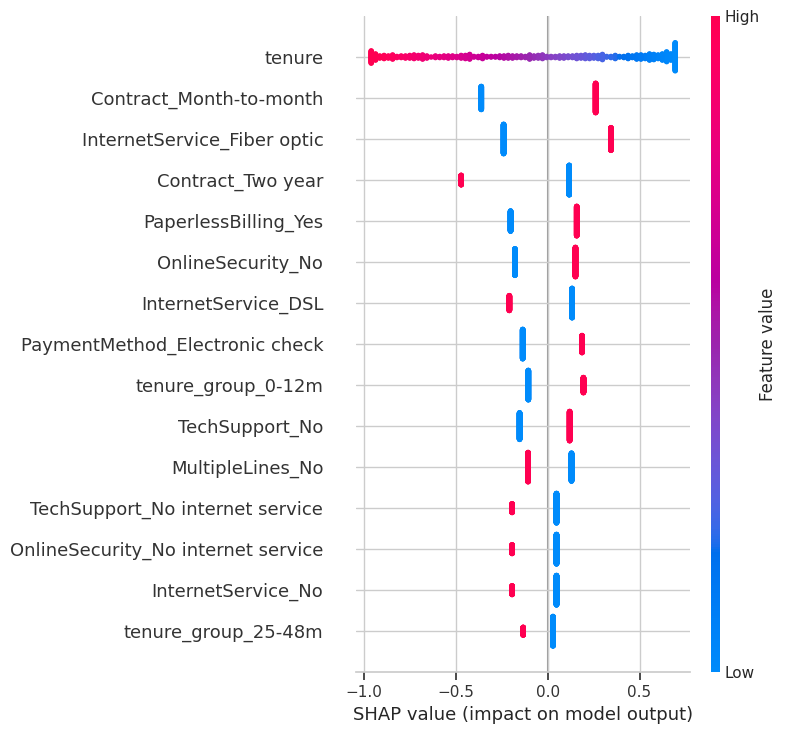

In [ ]:
r = permutation_importance(model, X_test[FEATURES], y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": FEATURES, "importance": r.importances_mean, "std": r.importances_std}).sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=imp, y="feature", x="importance", color="#4C78A8", ax=ax); ax.set_title("Permutation importance (drop in test ROC-AUC)")
plt.tight_layout(); plt.show()

try:   # SHAP works for linear and tree models
    import shap
    prep, clf = model.named_steps["prep"], model.named_steps["clf"]
    sample = X_test[FEATURES].sample(min(500, len(X_test)), random_state=RANDOM_STATE)
    Xt = pd.DataFrame(prep.transform(sample), columns=prep.get_feature_names_out())
    sv = shap.LinearExplainer(clf, Xt).shap_values(Xt) if hasattr(clf, "coef_") else shap.TreeExplainer(clf).shap_values(Xt)
    shap.summary_plot(sv[1] if isinstance(sv, list) else sv, Xt, show=True, max_display=15)
except Exception as e:
    print("SHAP skipped:", e)

Check against the Stage 01 success criteria

In [ ]:
achieved = {"roc_auc": metrics["roc_auc"], "recall": metrics["recall"], "top_decile_lift": float(lift.loc[1, "lift"])}
success = pd.DataFrame({k: {"target": t, "actual": round(achieved[k], 3), "met": achieved[k] >= t}
                        for k, t in SUCCESS_CRITERIA.items()}).T
display(success)
print("ALL SUCCESS CRITERIA MET" if success["met"].all() else "Some criteria NOT met: revisit features/threshold/model.")

,target,actual,met
roc_auc,0.8,0.839,True
recall,0.75,0.92,True
top_decile_lift,2.0,2.752,True


ALL SUCCESS CRITERIA MET


### **Stage 09:** Model Deployment

In [ ]:
def build_reference(X, numeric, categorical, ref_scores, baseline):
    ref = {"numeric": {}, "categorical": {}, "baseline": baseline}
    for c in numeric:
        edges = np.unique(np.quantile(X[c], np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
        cnt = np.histogram(X[c], edges)[0]
        ref["numeric"][c] = {"edges": [float(e) for e in edges], "share": (cnt / cnt.sum()).tolist()}
    for c in categorical:
        ref["categorical"][c] = X[c].value_counts(normalize=True).to_dict()
    edges = np.unique(np.quantile(ref_scores, np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
    cnt = np.histogram(ref_scores, edges)[0]
    ref["score"] = {"edges": [float(e) for e in edges], "share": (cnt / cnt.sum()).tolist()}
    return ref

baseline = {"roc_auc": metrics["roc_auc"], "recall": metrics["recall"], "predicted_churn_rate": float(pred.mean())}
reference = build_reference(X_train[FEATURES], numeric, categorical, oof, baseline)

joblib.dump({"pipeline": model, "threshold": threshold, "model_name": best_name, "best_params": search.best_params_,
             "numeric": numeric, "categorical": categorical, "reference": reference}, "churn_model.joblib")
print("Saved churn_model.joblib")

Saved churn_model.joblib


In [ ]:
artifact = joblib.load("churn_model.joblib")   # in a real service, load once at start-up

def prepare(df_raw):
    """Same stateless cleaning as training, tolerant of form/API-style input."""
    d = df_raw.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"].astype(str).str.strip(), errors="coerce")
    d["TotalCharges"] = d["TotalCharges"].fillna(d["MonthlyCharges"] * d["tenure"])
    if pd.api.types.is_numeric_dtype(d["SeniorCitizen"]):
        d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})
    return add_features(d)

def predict_churn(customers):
    """customers: DataFrame of raw rows, or a single dict."""
    df_raw = pd.DataFrame([customers]) if isinstance(customers, dict) else customers.copy()
    cols = artifact["numeric"] + artifact["categorical"]
    p = artifact["pipeline"].predict_proba(prepare(df_raw)[cols])[:, 1]
    out = df_raw.copy()
    out["churn_probability"] = p.round(4)
    out["churn_prediction"] = (p >= artifact["threshold"]).astype(int)
    out["risk_band"] = pd.cut(p, [-0.01, 0.3, 0.6, 1.0], labels=["low", "medium", "high"]).astype(str)
    return out

# Example: one new customer
new_customer = {"customerID": "NEW-001", "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
                "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
                "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
                "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
                "MonthlyCharges": 75.0, "TotalCharges": 150.0}
display(predict_churn(new_customer)[["customerID", "churn_probability", "churn_prediction", "risk_band"]])

# Batch scoring: the ten highest-risk customers in the test set
scored = predict_churn(test_df.drop(columns=[TARGET]))
scored.sort_values("churn_probability", ascending=False)[["customerID", "tenure", "Contract", "churn_probability", "risk_band"]].head(10)

,customerID,churn_probability,churn_prediction,risk_band
0,NEW-001,0.8869,1,high


,customerID,tenure,Contract,churn_probability,risk_band
38,4415-IJZTP,1,Month-to-month,0.9178,high
1221,0295-PPHDO,1,Month-to-month,0.9178,high
1090,5178-LMXOP,1,Month-to-month,0.9178,high
1109,1069-XAIEM,1,Month-to-month,0.9178,high
618,9248-OJYKK,1,Month-to-month,0.9178,high
1259,2609-IAICY,1,Month-to-month,0.9178,high
234,7180-PISOG,1,Month-to-month,0.9178,high
41,4927-WWOOZ,2,Month-to-month,0.9160,high
889,2545-EBUPK,2,Month-to-month,0.9160,high
828,7817-BOQPW,2,Month-to-month,0.9160,high


### **Stage 10:** Model Monitoring & Maintenance

In [ ]:
PSI_WARN, PSI_ALERT, AUC_DROP, RECALL_DROP, EPS = 0.10, 0.25, 0.05, 0.10, 1e-4

def _psi(expected, actual):
    e, a = np.clip(np.asarray(expected), EPS, None), np.clip(np.asarray(actual), EPS, None)
    return float(np.sum((a - e) * np.log(a / e)))
def _psi_num(ref, v):
    c = np.histogram(v, ref["edges"])[0]
    return _psi(ref["share"], c / max(c.sum(), 1))
def _psi_cat(ref, v):
    cats = list(ref) + ["__other__"]
    cur = v.where(v.isin(ref), "__other__").value_counts(normalize=True)
    return _psi([ref.get(c, 0.0) for c in cats], [cur.get(c, 0.0) for c in cats])
status = lambda x: "ALERT" if x > PSI_ALERT else "WARN" if x > PSI_WARN else "OK"

def monitor(df_raw, y_true=None, name="current"):
    ref = artifact["reference"]; X = prepare(df_raw)
    p = artifact["pipeline"].predict_proba(X[artifact["numeric"] + artifact["categorical"]])[:, 1]
    drift = pd.DataFrame([{"feature": c, "psi": _psi_num(r, X[c].to_numpy())} for c, r in ref["numeric"].items()] +
                         [{"feature": c, "psi": _psi_cat(r, X[c])} for c, r in ref["categorical"].items()])
    drift["status"] = drift["psi"].map(status)
    drift = drift.sort_values("psi", ascending=False).reset_index(drop=True)
    score_psi = _psi_num(ref["score"], p); alerts = []
    if (drift.status == "ALERT").any() or status(score_psi) == "ALERT":
        alerts.append("Major data/score drift: investigate upstream data and consider retraining.")
    rep = {"scenario": name, "rows": len(X),
           "predicted_churn_rate": round(float((p >= artifact["threshold"]).mean()), 3),
           "score_psi": round(score_psi, 3),
           "features_warn": drift.loc[drift.status == "WARN", "feature"].tolist(),
           "features_alert": drift.loc[drift.status == "ALERT", "feature"].tolist()}
    if y_true is not None:
        auc, rec = roc_auc_score(y_true, p), recall_score(y_true, p >= artifact["threshold"])
        rep["roc_auc"], rep["recall"] = round(auc, 3), round(rec, 3)
        if auc < ref["baseline"]["roc_auc"] - AUC_DROP:
            alerts.append(f"ROC-AUC fell to {auc:.3f} (baseline {ref['baseline']['roc_auc']:.3f}).")
        if rec < ref["baseline"]["recall"] - RECALL_DROP:
            alerts.append(f"Recall fell to {rec:.3f} (baseline {ref['baseline']['recall']:.3f}).")
    rep["overall"] = "ALERT" if alerts else "WARN" if rep["features_warn"] or status(score_psi) == "WARN" else "OK"
    rep["alerts"], rep["retrain_recommended"] = alerts, bool(alerts)
    return rep, drift

rng = np.random.default_rng(RANDOM_STATE)

data_drift = test_df.copy()        # synthetic: newer, pricier, more month-to-month fiber customers
data_drift["tenure"] = (data_drift["tenure"] * 0.5).astype(int)
data_drift["MonthlyCharges"] = (data_drift["MonthlyCharges"] * 1.25).round(2)
data_drift["TotalCharges"] = (data_drift["tenure"] * data_drift["MonthlyCharges"]).round(2)
sw = rng.random(len(data_drift)) < 0.4
data_drift.loc[sw, ["Contract", "InternetService"]] = ["Month-to-month", "Fiber optic"]

concept_drift = test_df.copy()     # synthetic: same inputs, but 25% of outcomes no longer follow the learned pattern
flip = rng.random(len(concept_drift)) < 0.25
concept_drift.loc[flip, TARGET] = rng.integers(0, 2, flip.sum())

results, drift_tables = [], {}
for name, data in {"stable_holdout": test_df, "data_drift_synthetic": data_drift,
                   "concept_drift_synthetic": concept_drift}.items():
    rep, drift_tables[name] = monitor(data, data[TARGET], name); results.append(rep)
display(pd.DataFrame(results)[["scenario", "overall", "score_psi", "roc_auc", "recall", "predicted_churn_rate", "retrain_recommended"]])
for r_ in results:
    if r_["alerts"]:
        print(f"[{r_['scenario']}]", *r_["alerts"], sep="\n   - ")

,scenario,overall,score_psi,roc_auc,recall,predicted_churn_rate,retrain_recommended
0,stable_holdout,OK,0.006,0.839,0.920,0.574,False
1,data_drift_synthetic,ALERT,0.276,0.813,0.981,0.779,True
2,concept_drift_synthetic,ALERT,0.006,0.721,0.770,0.574,True


[data_drift_synthetic]
   - Major data/score drift: investigate upstream data and consider retraining.
[concept_drift_synthetic]
   - ROC-AUC fell to 0.721 (baseline 0.839).
   - Recall fell to 0.770 (baseline 0.920).


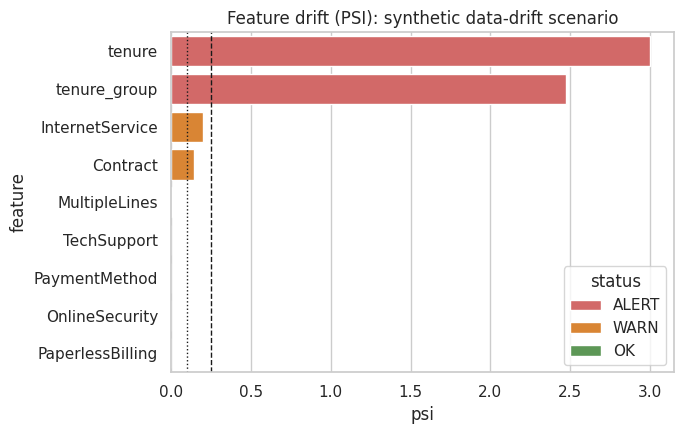

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=drift_tables["data_drift_synthetic"], y="feature", x="psi", hue="status", dodge=False, ax=ax,
            palette={"OK": "#54A24B", "WARN": "#F58518", "ALERT": "#E45756"})
ax.axvline(PSI_WARN, color="k", ls=":", lw=1); ax.axvline(PSI_ALERT, color="k", ls="--", lw=1)
ax.set_title("Feature drift (PSI): synthetic data-drift scenario"); plt.tight_layout(); plt.show()